In [ ]:
# 1. Các chỉ báo kỹ thuật (Indicators)
# ATR (Average True Range): Sử dụng rất nhiều chu kỳ:
# ATR(40): Dùng để xác định trạng thái nén của thị trường.
# ATR(30): Dùng để tính điểm vào lệnh (Entry Price).
# ATR(20): Dùng để tính Stop Loss.
# ATR(25): Dùng để tính Profit Target.
# Keltner Channel (KC): Chu kỳ 20, Hệ số nhân (Multiplier) 2.5. Dùng làm nền tảng (Base) để đặt lệnh chờ.
# 2. Tín hiệu Setup (Môi trường)
# Chiến lược này tìm kiếm thời điểm Biến động đang giảm dần (Lò xo đang nén).
# Điều kiện: ATR(40) của cây nến trước nữa > ATR(40) của cây nến vừa đóng.
# Code: sqATR(..., shift=2) > sqATR(..., shift=1).
# Ý nghĩa: Độ biến động đang giảm xuống. Thị trường đang bình ổn lại để chuẩn bị cho cú phá vỡ tiếp theo.
# 3. Điểm vào lệnh (Entry Execution)
# Sử dụng Lệnh Chờ (Stop Order) đặt cách xa dải Keltner.
# Buy Stop: KC_Upper(2.5) + (1.4 * ATR(30)).
# Sell Stop: KC_Lower(2.5) - (1.4 * ATR(30)).
# Lưu ý: Giá phải phá vỡ dải Keltner (vốn đã rộng 2.5 độ lệch) cộng thêm một khoảng đệm 1.4 ATR nữa. Đây là điểm vào lệnh cực kỳ an toàn, chỉ khớp khi có "Siêu sóng".
# Hủy lệnh (Expiration): Sau 7 cây nến.
# 4. Thoát lệnh (Exit)
# Stop Loss: 1.8 * ATR(20). (Khá chặt).
# Profit Target: 4.7 * ATR(25). (Tỷ lệ R:R cực cao > 1:2.5).
# Trailing Stop: Cố định 100 giá (Points/Pips).
# Khác với các chiến lược trước dùng ATR để Trailing, chiến lược này dùng con số cố định (TrailingStop = 100). Với BTC, ta hiểu là 100 USDT.
# Time Exit: Thoát sau 28 cây nến (Hơn 1 ngày).


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.3/240.3 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 14.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.1 which is incompatible.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.2.6 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.1 which is incomp

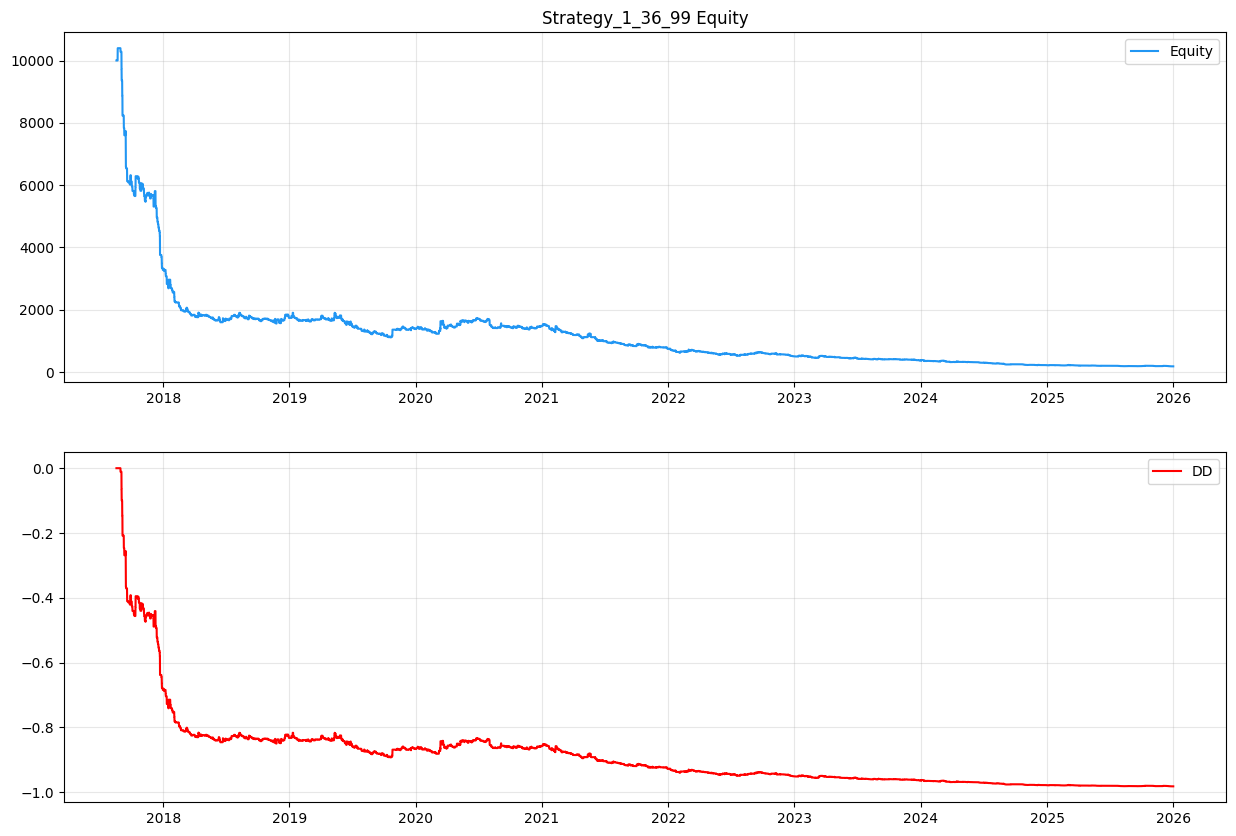

In [1]:
# ==============================================================================
# BƯỚC 1: CÀI ĐẶT THƯ VIỆN
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# BƯỚC 2: CẤU HÌNH CHIẾN LƯỢC (Strategy_1_36_99 - Volatility Compression)
# ==============================================================================
CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'INTERVAL': '1h',
    'START_DATE': '01/01/2015',
    'END_DATE': '31/12/2025',
    'INITIAL_CAPITAL': 10000.0,

    # --- Indicators ---
    'KC_PERIOD': 20,
    'KC_MULT': 2.5,          # Độ lệch chuẩn Keltner (Rộng hơn chuẩn 2.0)

    'ATR_SETUP_PERIOD': 40,  # ATR xác định nén (Falling)
    'ATR_ENTRY_PERIOD': 30,  # ATR tính Buffer vào lệnh (MTATRPeriod)

    'ATR_SL_PERIOD': 20,     # ATR tính SL
    'ATR_PT_PERIOD': 25,     # ATR tính PT

    # --- Entry & Management ---
    'ENTRY_MULT': 1.4,       # Hệ số nhân với ATR(30)
    'SL_COEF': 1.8,          # 1.8 * ATR(20)
    'PT_COEF': 4.7,          # 4.7 * ATR(25)

    'USE_FIXED_TRAIL': True, # Sử dụng Trailing cố định thay vì ATR
    'TRAIL_DIST': 100.0,     # Trailing 100 giá (USDT)

    'ORDER_EXPIRATION': 7,   # Hủy lệnh sau 7 nến
    'TIME_EXIT_BARS': 28,    # Thoát sau 28 nến

    # Costs
    'FEE_RATE': 0.0004,
    'SLIPPAGE': 0.0002
}

# ==============================================================================
# BƯỚC 3: MODULE TẢI DỮ LIỆU
# ==============================================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://data-api.binance.vision/"
    url = base_url + "api/v3/klines"
    req_symbol = symbol.upper()

    print(f"📡 Checking connection to Binance...")
    try:
        test = requests.get(f"{base_url}/api/v3/time", timeout=5)
        if test.status_code == 451:
            print("⚠️ US IP detected. Switching to Binance.US...")
            base_url = "https://api.binance.us"
            if req_symbol == "BTCUSDT": req_symbol = "BTCUSD"
    except:
        print("⚠️ Connection failed. Retrying with Binance.US...")
        base_url = "https://api.binance.us"
        req_symbol = "BTCUSD"

    url = base_url + "/api/v3/klines"
    start_time = str_to_millis(start_str)

    if end_str == datetime.now().strftime("%d/%m/%Y"):
        end_time = int(time.time() * 1000)
    else:
        end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
        end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {req_symbol} ({interval}) from {base_url}...")

    while start_time < end_time:
        params = {"symbol": req_symbol, "interval": interval, "startTime": start_time, "endTime": end_time, "limit": 1000}
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200: break
            data = r.json()
            if not data: break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            if len(all_klines) % 5000 == 0:
                print(f"   -> Downloaded: {len(all_klines)} candles")
            time.sleep(0.05)
        except: break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=["timestamp", "Open", "High", "Low", "Close", "Volume", "CT", "QAV", "NT", "TBBV", "TBQV", "I"])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    print(f"✅ Total: {len(df)} candles.")
    return df

# ==============================================================================
# BƯỚC 4: BACKTEST ENGINE (Logic Strategy_1_36_99)
# ==============================================================================
def run_strategy(df):
    print("⚙️ Calculating indicators & Running Strategy_1_36_99...")
    df = df.copy()
    c = CONFIG

    # --- A. INDICATORS ---
    # 1. Keltner Channels (20, 2.5) - Basis là SMA
    kc_basis = ta.sma(df['Close'], length=c['KC_PERIOD'])
    kc_range = ta.atr(df['High'], df['Low'], df['Close'], length=c['KC_PERIOD'])
    df['KC_Upper'] = kc_basis + (c['KC_MULT'] * kc_range)
    df['KC_Lower'] = kc_basis - (c['KC_MULT'] * kc_range)

    # 2. ATRs
    df['ATR_Setup'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_SETUP_PERIOD'])
    df['ATR_Entry'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_ENTRY_PERIOD'])
    df['ATR_SL']    = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_SL_PERIOD'])
    df['ATR_PT']    = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_PT_PERIOD'])

    df.dropna(inplace=True)

    # --- B. INITIALIZATION ---
    capital = c['INITIAL_CAPITAL']
    position = 0; entry_price = 0.0; entry_idx = 0
    sl_price = 0.0; tp_price = 0.0
    pending_orders = []; trades = []
    equity_curve = [c['INITIAL_CAPITAL']] * len(df)

    # Numpy Arrays
    opens = df['Open'].values; highs = df['High'].values; lows = df['Low'].values; closes = df['Close'].values
    times = df.index

    # Indicators Array
    kc_upper = df['KC_Upper'].values; kc_lower = df['KC_Lower'].values
    atr_setup = df['ATR_Setup'].values
    atr_entry = df['ATR_Entry'].values
    atr_sl = df['ATR_SL'].values; atr_pt = df['ATR_PT'].values

    # --- C. MAIN LOOP ---
    for i in range(1, len(df)):

        # 1. QUẢN LÝ LỆNH ĐANG CHẠY (EXIT)
        if position != 0:
            exit_signal = False; exit_reason = ""; raw_exit_price = closes[i]

            if position == 1:
                if lows[i] <= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif highs[i] >= tp_price:
                    exit_signal = True; exit_reason = "PT Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']:
                    exit_signal = True; exit_reason = "Time Exit"; raw_exit_price = closes[i]

            elif position == -1:
                if highs[i] >= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif lows[i] <= tp_price:
                    exit_signal = True; exit_reason = "PT Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']:
                    exit_signal = True; exit_reason = "Time Exit"; raw_exit_price = closes[i]

            if exit_signal:
                # Tính PnL
                if position == 1:
                    real_exit = min(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 - c['SLIPPAGE'])
                    pnl = (real_exit - entry_price) / entry_price
                else:
                    real_exit = max(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 + c['SLIPPAGE'])
                    pnl = (entry_price - real_exit) / entry_price

                net_pnl = pnl - (c['FEE_RATE'] * 2)
                capital += (capital * net_pnl)

                trades.append({'Date': times[i], 'Type': 'Long' if position == 1 else 'Short', 'Reason': exit_reason, 'PnL': capital * net_pnl, 'Equity': capital})
                position = 0; pending_orders = []

            else:
                # TRAILING STOP (FIXED PIPS)
                if c['USE_FIXED_TRAIL']:
                    dist = c['TRAIL_DIST']
                    if position == 1:
                        new_sl = closes[i] - dist
                        if new_sl > sl_price: sl_price = new_sl
                    elif position == -1:
                        new_sl = closes[i] + dist
                        if new_sl < sl_price: sl_price = new_sl

        # 2. XỬ LÝ LỆNH CHỜ (ENTRY)
        if position == 0:
            # Lọc lệnh hết hạn (7 nến)
            pending_orders = [o for o in pending_orders if (i - o['created_idx']) < c['ORDER_EXPIRATION']]

            triggered = None
            for order in pending_orders:
                if order['type'] == 'buy' and highs[i] >= order['price']:
                    triggered = order; exec_price = max(opens[i], order['price']) if opens[i] > order['price'] else order['price']
                    break
                elif order['type'] == 'sell' and lows[i] <= order['price']:
                    triggered = order; exec_price = min(opens[i], order['price']) if opens[i] < order['price'] else order['price']
                    break

            if triggered:
                entry_idx = i
                if triggered['type'] == 'buy':
                    position = 1
                    entry_price = exec_price * (1 + c['SLIPPAGE'])
                    sl_price = exec_price - (c['SL_COEF'] * atr_sl[i])
                    tp_price = exec_price + (c['PT_COEF'] * atr_pt[i])
                else:
                    position = -1
                    entry_price = exec_price * (1 - c['SLIPPAGE'])
                    sl_price = exec_price + (c['SL_COEF'] * atr_sl[i])
                    tp_price = exec_price - (c['PT_COEF'] * atr_pt[i])

                pending_orders = []

        # 3. TẠO TÍN HIỆU MỚI (Logic Strategy_1_36_99)
        if position == 0:
            # Setup: ATR Falling (Shift 2 > Shift 1)
            # Trong backtest vector: atr[i-2] > atr[i-1]
            atr_falling = atr_setup[i-2] > atr_setup[i-1]

            # Entry Calculation: KC +/- (1.4 * ATR(30))
            buffer = c['ENTRY_MULT'] * atr_entry[i]
            buy_price = kc_upper[i] + buffer
            sell_price = kc_lower[i] - buffer

            if atr_falling:
                # Chiến lược này đặt cả Buy Stop và Sell Stop khi có nén biến động
                pending_orders.append({'type': 'buy', 'price': buy_price, 'created_idx': i})
                pending_orders.append({'type': 'sell', 'price': sell_price, 'created_idx': i})

        equity_curve[i] = capital

    return pd.Series(equity_curve, index=df.index), pd.DataFrame(trades)

# ==============================================================================
# BƯỚC 5: RUN & REPORT
# ==============================================================================
if __name__ == "__main__":
    df = fetch_binance_kline_df(CONFIG['SYMBOL'], CONFIG['INTERVAL'], CONFIG['START_DATE'], CONFIG['END_DATE'])

    if not df.empty:
        equity, trades_df = run_strategy(df)

        if not trades_df.empty:
            final_equity = equity.iloc[-1]
            total_return = (final_equity - CONFIG['INITIAL_CAPITAL']) / CONFIG['INITIAL_CAPITAL']

            rolling_max = equity.cummax()
            dd = (equity - rolling_max) / rolling_max
            max_dd = dd.min()

            wins = trades_df[trades_df['PnL'] > 0]
            losses = trades_df[trades_df['PnL'] <= 0]
            winrate = len(wins) / len(trades_df) if len(trades_df) > 0 else 0

            gross_profit = wins['PnL'].sum(); gross_loss = abs(losses['PnL'].sum())
            profit_factor = gross_profit / gross_loss if gross_loss != 0 else 0

            days = (equity.index[-1] - equity.index[0]).days
            cagr = ((final_equity / CONFIG['INITIAL_CAPITAL']) ** (365.0 / days)) - 1 if days > 0 else 0

            returns = equity.pct_change().dropna()
            sharpe_ratio = (returns.mean() / returns.std()) * np.sqrt(365 * 24) if returns.std() != 0 else 0

            print(f"\n{'='*30}")
            print(f"📊 BACKTEST: Strategy_1_36_99 ({CONFIG['SYMBOL']})")
            print(f"{'='*30}")
            print(f"{'Final Equity:':>15} {final_equity:,.2f}")
            print(f"{'Total Return:':>15} {total_return:.2%}")
            print(f"{'CAGR (approx):':>15} {cagr:.2%}")
            print(f"{'Max Drawdown:':>15} {max_dd:.2%}")
            print(f"{'Sharpe Ratio:':>15} {sharpe_ratio:.2f}")
            print(f"{'Trades:':>15} {len(trades_df)}")
            print(f"{'Winrate:':>15} {winrate:.2%}")
            print(f"{'Profit Factor:':>15} {profit_factor:.2f}")
            print(f"{'='*30}")

            plt.figure(figsize=(15, 10))
            plt.subplot(2, 1, 1)
            plt.plot(equity, label='Equity', color='#2196F3'); plt.grid(True, alpha=0.3); plt.legend()
            plt.title('Strategy_1_36_99 Equity')
            plt.subplot(2, 1, 2)
            plt.plot(dd, label='DD', color='red'); plt.grid(True, alpha=0.3); plt.legend()
            plt.show()
        else:
            print("⚠️ No trades executed.")
    else:
        print("❌ No data.")